# 01 — Preprocessing
**KhabarNazar — Image Analysis Module**

### Why this step is needed
The data check (notebook 00) showed that real and fake images differ in **size** and **file format**:

| Dataset | Real images | Fake images |
|---|---|---|
| AI vs Real | many sizes, up to 3072×4608 | mostly ~1024 px |
| Misinfo | ~640 px | 1024×1024 |

A model can "cheat" by learning *big image → real* or *PNG → fake* instead of learning genuine AI-generation
artifacts. This is called **shortcut learning**. To remove these shortcuts, every image from every dataset is
processed **in exactly the same way**:

1. Convert to RGB
2. Resize so the **shorter side = 512 px** (images smaller than 224 px are enlarged to 224)
3. Save as **JPEG, quality 95** (same format and compression for real and fake)

Output: `data/processed/<dataset>/<split>/<real|fake>/*.jpg` — the folder layout every later notebook uses.
The notebook can be safely re-run: images that are already processed are skipped.

In [1]:
import io, time, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from PIL import Image, ImageFile
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True
Image.MAX_IMAGE_PIXELS = None

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
OUT = DATA / "processed"
OUTPUTS = ROOT / "outputs"; OUTPUTS.mkdir(exist_ok=True)
IMG_EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}

SHORT_SIDE = 512     # target size of the shorter side
MIN_SIDE = 224       # never smaller than the model's input size
JPEG_QUALITY = 95
WORKERS = 8          # parallel threads

## 1. The standardisation function

In [2]:
def standardise(img):
    img = img.convert("RGB")
    w, h = img.size
    short = min(w, h)
    target = SHORT_SIDE if short > SHORT_SIDE else max(short, MIN_SIDE)
    if target != short:
        scale = target / short
        img = img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.BICUBIC)
    return img

def save_image(job):
    # job = (source, destination); source is a file path or raw image bytes
    src, dst = job
    if dst.exists():
        return None
    try:
        img = Image.open(io.BytesIO(src)) if isinstance(src, (bytes, bytearray)) else Image.open(src)
        dst.parent.mkdir(parents=True, exist_ok=True)
        standardise(img).save(dst, "JPEG", quality=JPEG_QUALITY)
        return None
    except Exception as e:
        return f"{dst.name}: {e}"

def run_jobs(jobs, desc):
    errors = []
    with ThreadPoolExecutor(WORKERS) as pool:
        for err in tqdm(pool.map(save_image, jobs), total=len(jobs), desc=desc):
            if err:
                errors.append(err)
    print(f"{desc}: {len(jobs) - len(errors)} ok, {len(errors)} failed")
    for e in errors[:10]:
        print("  ", e)
    return errors

## 2. AI vs Real
`train/real`, `train/fake`, `test/real`, `test/fake` → `processed/ai_vs_real/...`

In [3]:
SRC = DATA / "ai_vs_real"
jobs = []
for split in ["train", "test"]:
    for cls in ["real", "fake"]:
        for p in sorted((SRC / split / cls).iterdir()):
            if p.suffix.lower() in IMG_EXT:
                jobs.append((p, OUT / "ai_vs_real" / split / cls / f"{p.stem}.jpg"))
start = time.time()
run_jobs(jobs, "AI vs Real")
print(f"Time: {(time.time() - start) / 60:.1f} min")

AI vs Real:   0%|          | 0/60000 [00:00<?, ?it/s]

E:\FYP\KhabarNazar\image_module\venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


AI vs Real: 60000 ok, 0 failed
Time: 14.7 min


## 3. Tiny-GenImage
Parquet files → `processed/tiny_genimage/<train|val>/<real|fake>/<generator>_<n>.jpg`.
The generator name is kept in the file name so later notebooks can test on **unseen generators**.

In [4]:
TINY = DATA / "tiny_genimage"
GEN_NAMES = ["Real", "ADM", "BigGAN", "GLIDE", "Midjourney", "SD14", "SD15", "VQDM", "Wukong"]
LABELS = {0: "real", 1: "fake"}

for split, key in [("train", "train"), ("val", "valid")]:
    files = sorted(f for f in TINY.rglob("*.parquet") if key in f.name)
    jobs, n = [], 0
    for f in files:
        for batch in pq.ParquetFile(f).iter_batches(batch_size=256):
            for row in batch.to_pylist():
                gen = GEN_NAMES[row["generator"]]
                dst = OUT / "tiny_genimage" / split / LABELS[row["label"]] / f"{gen}_{n:06d}.jpg"
                jobs.append((row["image"]["bytes"], dst))
                n += 1
    run_jobs(jobs, f"Tiny-GenImage {split}")
    del jobs

Tiny-GenImage train:   0%|          | 0/28000 [00:00<?, ?it/s]

Tiny-GenImage train: 28000 ok, 0 failed


Tiny-GenImage val:   0%|          | 0/7000 [00:00<?, ?it/s]

Tiny-GenImage val: 7000 ok, 0 failed


## 4. Misinfo-dataset
`<generator>/val/ai` → fake, `<generator>/val/nature` → real. Test-only, never used for training.
The generator name is kept in the file name for per-generator results.

In [5]:
MIS = DATA / "misinfo"
jobs = []
for gen_dir in sorted(d for d in MIS.iterdir() if d.is_dir()):
    for sub, cls in [("ai", "fake"), ("nature", "real")]:
        folder = gen_dir / "val" / sub
        if not folder.exists():
            print("missing:", folder)
            continue
        for p in sorted(folder.iterdir()):
            if p.suffix.lower() in IMG_EXT:
                jobs.append((p, OUT / "misinfo" / "test" / cls / f"{gen_dir.name}_{p.stem}.jpg"))
run_jobs(jobs, "Misinfo")

Misinfo:   0%|          | 0/8000 [00:00<?, ?it/s]

Misinfo: 8000 ok, 0 failed


[]

## 5. Check the result

In [6]:
rows = []
for d in sorted(OUT.glob("*/*/*")):
    if d.is_dir():
        files = sorted(d.glob("*.jpg"))
        sizes = [Image.open(f).size for f in files[:200]]
        avg = f"{sum(s[0] for s in sizes) // len(sizes)}x{sum(s[1] for s in sizes) // len(sizes)}" if sizes else "-"
        rows.append({"dataset": d.parent.parent.name, "split": d.parent.name, "class": d.name,
                     "images": len(files), "avg size (first 200)": avg})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUTS / "01_processed_summary.csv", index=False)

,dataset,split,class,images,avg size (first 200)
0,ai_vs_real,test,fake,6000,537x552
1,ai_vs_real,test,real,6000,611x577
2,ai_vs_real,train,fake,24000,530x541
3,ai_vs_real,train,real,24000,642x600
4,misinfo,test,fake,4000,512x512
5,misinfo,test,real,4000,590x498
6,tiny_genimage,train,fake,14000,256x256
7,tiny_genimage,train,real,14000,473x369
8,tiny_genimage,val,fake,3500,256x256
9,tiny_genimage,val,real,3500,466x418


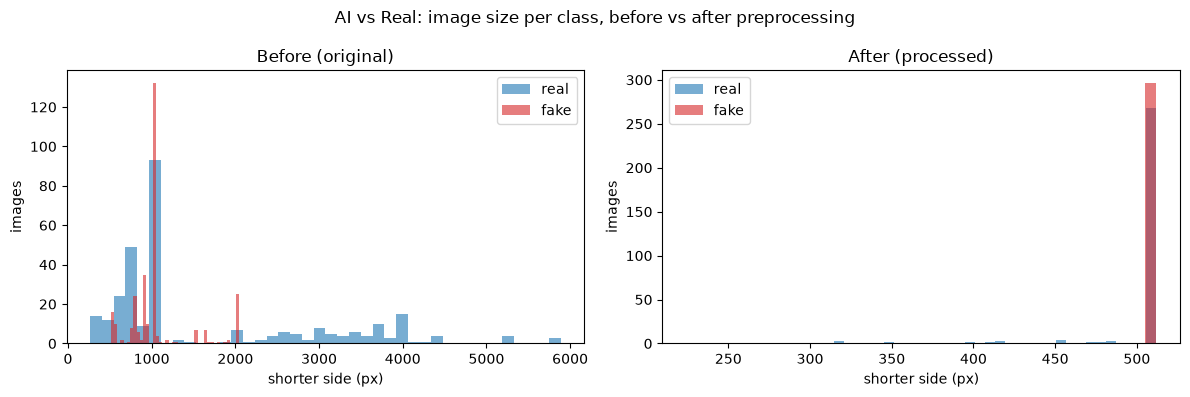

In [7]:
# Shorter-side size of 300 random images per class, before vs after processing (AI vs Real)
random.seed(0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (title, base) in zip(axes, [("Before (original)", DATA / "ai_vs_real"),
                                     ("After (processed)", OUT / "ai_vs_real")]):
    for cls, colour in [("real", "tab:blue"), ("fake", "tab:red")]:
        files = [p for p in (base / "train" / cls).iterdir() if p.suffix.lower() in IMG_EXT]
        sizes = [min(Image.open(p).size) for p in random.sample(files, 300)]
        ax.hist(sizes, bins=40, alpha=0.6, label=cls, color=colour)
    ax.set_title(title); ax.set_xlabel("shorter side (px)"); ax.set_ylabel("images"); ax.legend()
plt.suptitle("AI vs Real: image size per class, before vs after preprocessing")
plt.tight_layout(); plt.savefig(OUTPUTS / "01_size_before_after.png", dpi=120); plt.show()

Before processing, real and fake images have different size distributions. After processing, both classes
are capped at 512 px, so image size can no longer be used as a shortcut.

Next: **02_train_ai_vs_real.ipynb**.